# TikTok BNPL corpus: analysis

Builds the labelled, pseudonymized corpus from `data/raw/tiktok/` and produces the tables in `outputs/tiktok/tables/`, the figures in `outputs/figures/tiktok/`, and `outputs/tiktok/findings_summary.md`. Rerunning regenerates everything from the raw files.

**How to read this notebook.** The corpus is public TikTok content from accounts registered in Italy that names a BNPL provider or phrase. It is not a sample of the 20-27 study population: the API reports no age. Post types, creator types, and theme cues are transparent text rules defined in `scripts/tiktok_terms.py`; percentages are *mention rates* in captions, hashtags, and automatic transcripts, not validated prevalence. Only aggregates are displayed. Each result is followed by a short interpretation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'scripts').is_dir(): PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
from scripts import tiktok_analysis as analysis

result = analysis.run_analysis()
plt.close('all')
tables = result['tables']


def show(name):
    display(Image(filename=str(analysis.FIGURES_TIKTOK / f'{name}.png'), width=820))

## 1. Corpus and coverage

In [2]:
monthly = tables['monthly']
complete = monthly.loc[monthly['complete'], 'month']
display(result['funnel'])
print(f"Fully collected months: {complete.iloc[0]} to {complete.iloc[-1]} ({len(complete)} months)")
print(f"Creators: {result['corpus']['creator_id'].nunique():,}; "
      f"profiled: {int(result['creators']['profiled'].sum()):,}; "
      f"comments: {len(result['comments']):,}")
videos_per_creator = result['corpus']['creator_id'].value_counts()
print(f"Share of videos by the 10 / 100 most active creators: "
      f"{videos_per_creator.head(10).sum() / len(result['corpus']):.0%} / "
      f"{videos_per_creator.head(100).sum() / len(result['corpus']):.0%}")

,step,videos
0,records returned by the API,98641
1,unique video IDs,98641
2,"BNPL provider or phrase in description, hashta...",97166


Fully collected months: 2024-01 to 2026-08 (32 months)
Creators: 8,099; profiled: 997; comments: 18,078
Share of videos by the 10 / 100 most active creators: 15% / 47%


**Interpretation.** The search is precise: 97,166 of the 98,641 videos returned (98.5%) name a BNPL provider or phrase. The trend analysis uses the 32 fully collected months, January 2024 to August 2026. The weeks from 14 September to 18 October 2026 are still pending, because the daily video quota was reached; rerun the collection notebook to add them.

Production is concentrated. 8,099 accounts posted BNPL content, but the 100 most active accounts produced 47% of all videos and the top 10 produced 15%. Creator profiles cover 997 of the 2,348 selected accounts so far, again because of the daily quota. Comments cover 309 videos, which are the most-commented videos of each post type. Only 20% of videos have an automatic transcript, so captions and hashtags carry most of the signal.

*These figures describe the run of 26 October 2026. Rerunning the notebooks updates the tables and figures, but not this text.*

## 2. Volume over time

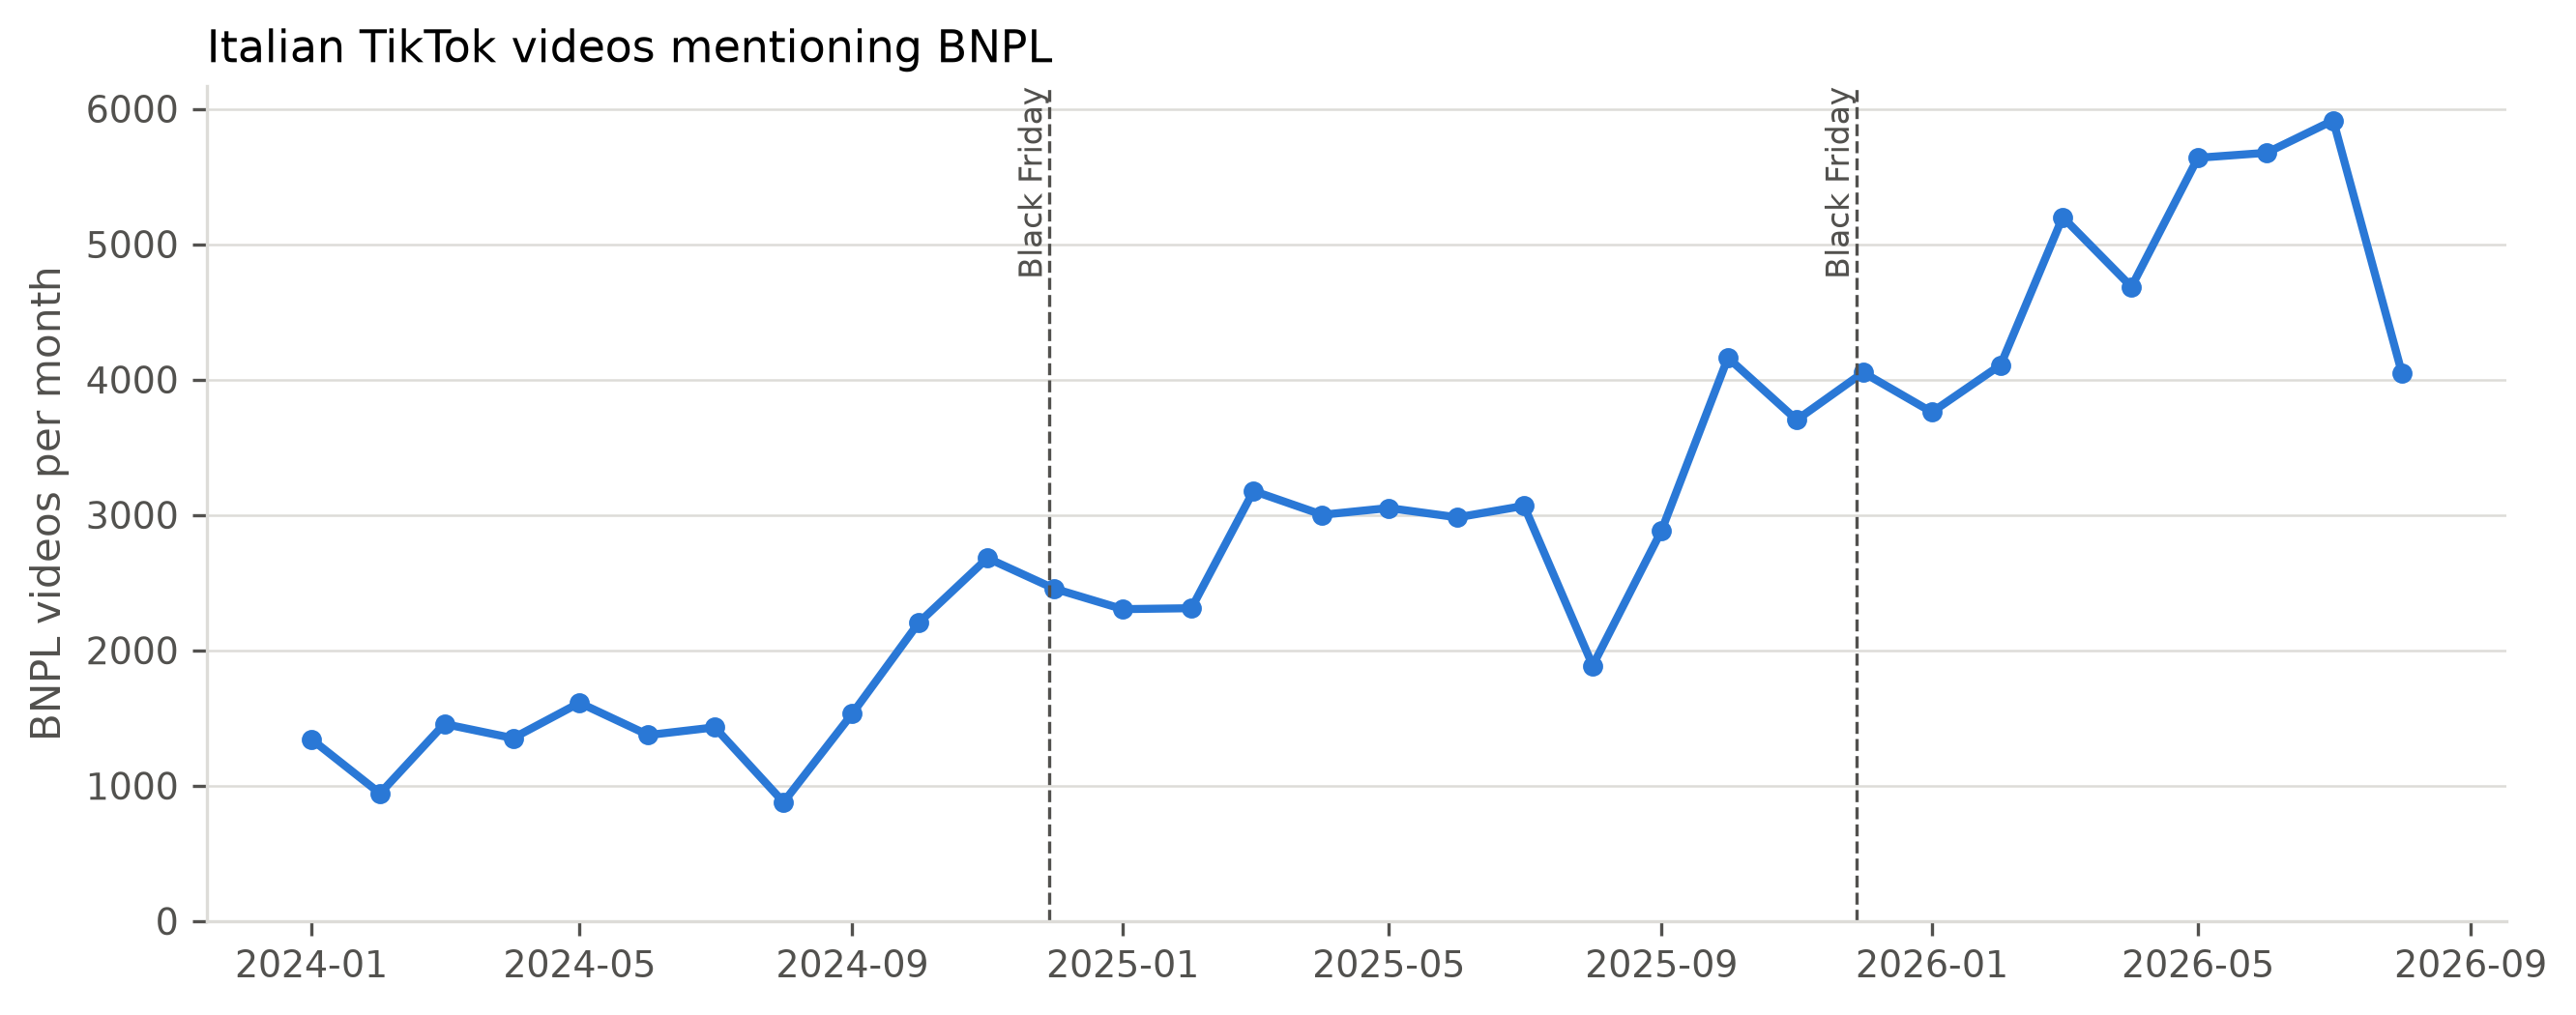

In [3]:
show('monthly_volume')

**Interpretation.** BNPL content on Italian TikTok roughly quadrupled in two and a half years: from about 1,300-1,600 videos a month in the first half of 2024 to 5,600-5,900 in May-July 2026, peaking in July 2026 (5,914). The growth comes in steps, in autumn 2024 (September-November) and in autumn 2025 (September-October), rather than evenly.

August is the low point every year (878, 1,887, and 4,048 videos), which fits the summer closure of the small shops that produce most of the content (see section 3).

The trend combines real growth in BNPL as a checkout option with growth of TikTok itself and changes in API coverage. It shows that exposure is rising, not by how much usage is rising.

## 3. Who posts, and what kind of post

,post_type,videos,creators,median_views,median_likes,median_comments,median_shares,share
0,personal_experience,37,25,"4,068.000",52.000,5.000,2.000,0.000
1,financial_commentary,159,137,"1,047.000",19.000,1.000,1.000,0.002
2,shop_ad,88403,6956,"1,061.000",13.000,0.000,1.000,0.910
3,other,8567,2001,847.000,11.000,0.000,1.000,0.088


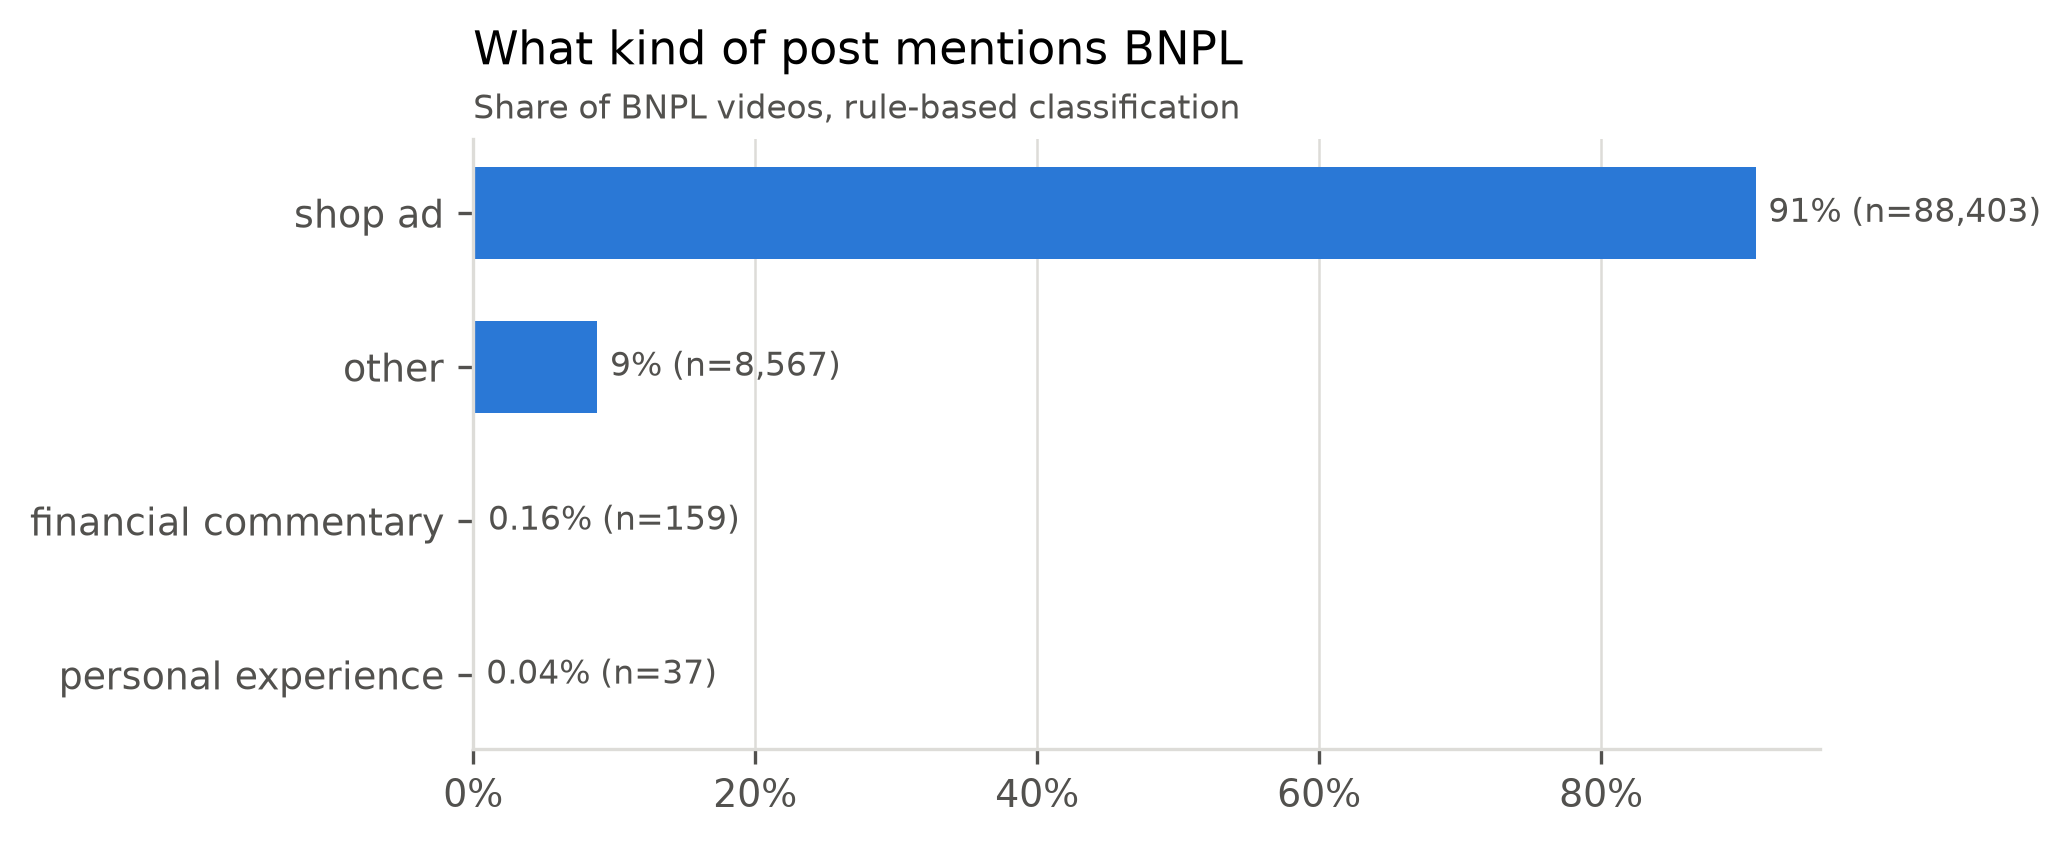

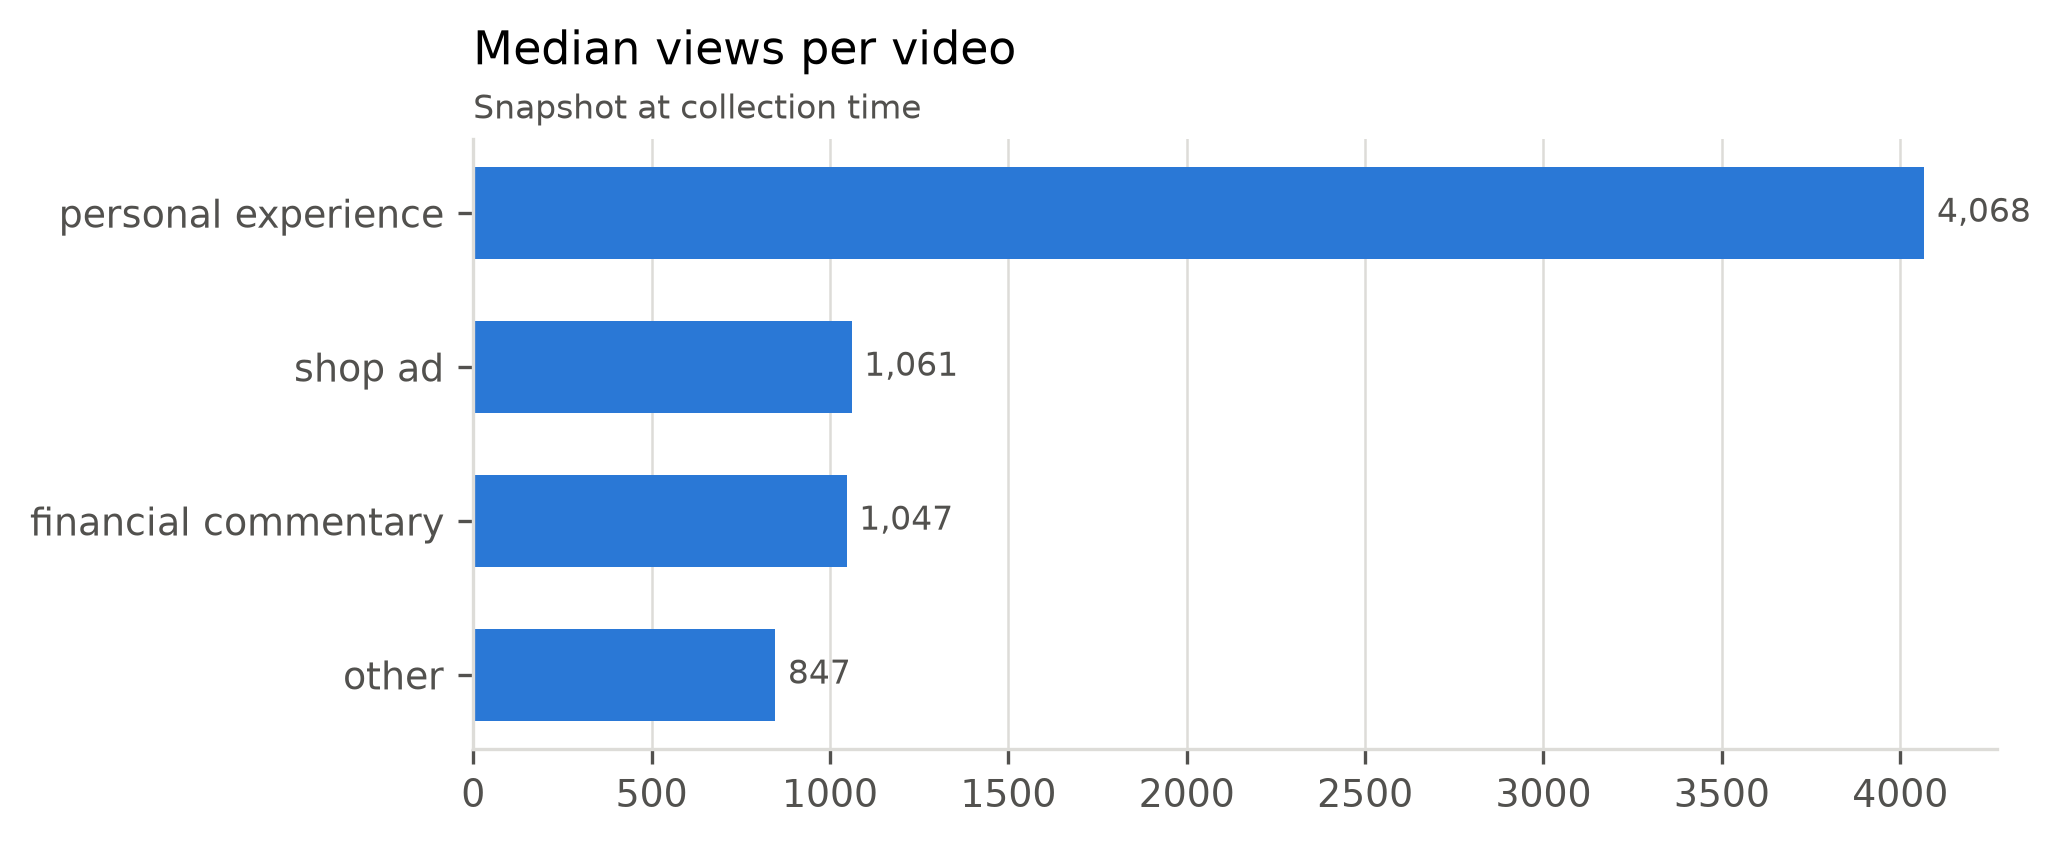

In [4]:
display(tables['post_types'])
show('post_types')
show('engagement_by_post_type')

**Interpretation.** On Italian TikTok, BNPL is overwhelmingly a merchant's selling argument rather than a topic people discuss.
- **Shop ads:** 91% of videos. Shops and services list "paga in 3 rate con Klarna/Scalapay" next to prices, shipping, and WhatsApp contacts.
- **Other:** 9%, mostly hashtag-only posts from the same kind of accounts.
- **Financial commentary:** 159 videos, 0.16% of the corpus. These are explainers, warnings, and news.
- **First-person posts:** 37 videos, 0.04%. Reading them shows that about half are creator product reviews rather than independent accounts of using BNPL.

Engagement does not rescue the critical voice. Commentary has the same median reach as an ad (about 1,050 views). First-person posts reach more people (median 4,068 views), but there are only 37 of them.

For the thesis: young adults who meet BNPL on TikTok meet it mainly as a promotional checkout feature, not as credit discussed by peers.

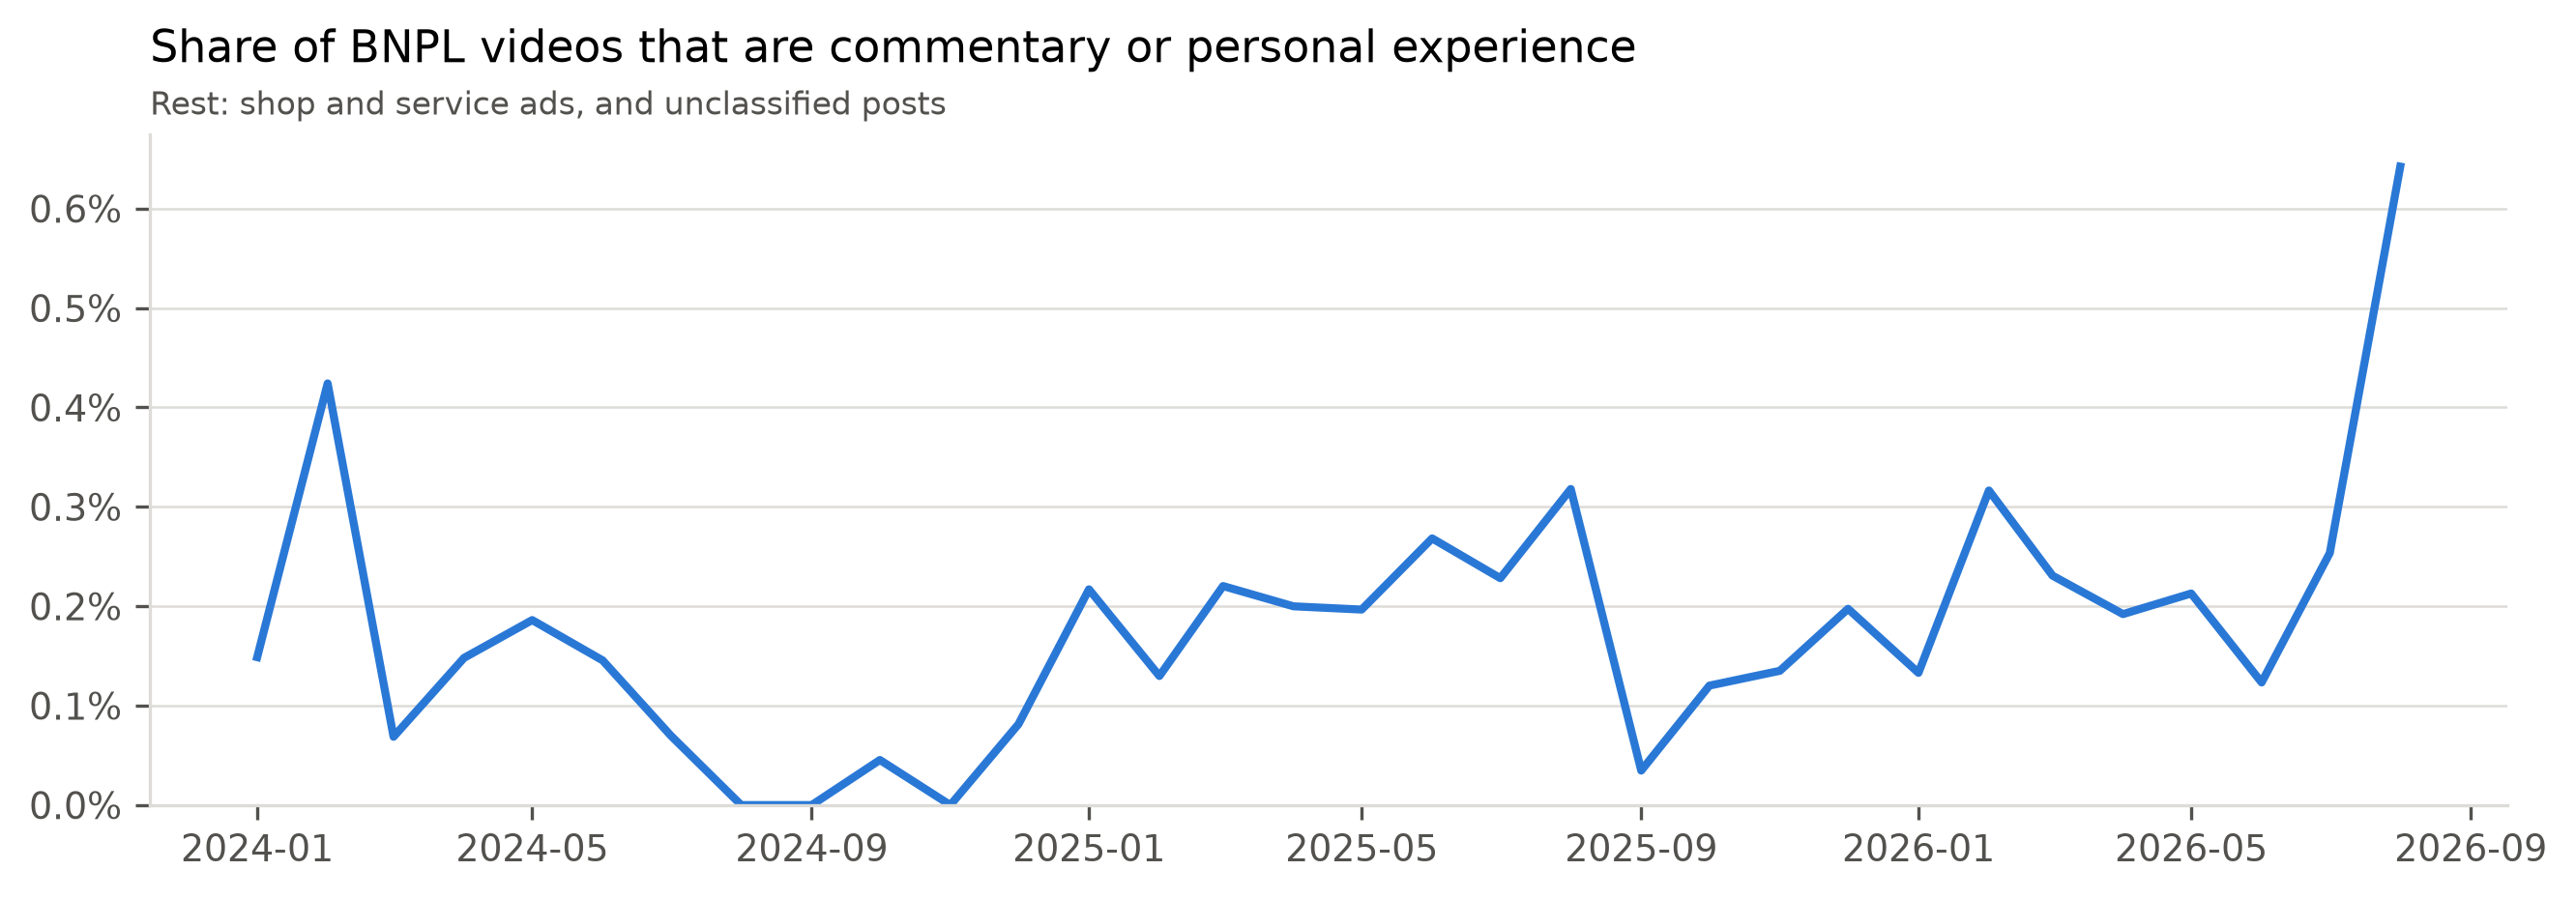

In [5]:
show('discourse_share')

**Interpretation.** Commentary and first-person posts stay mostly between 0.1% and 0.3% of BNPL videos from 2024 to mid-2026 (the 0.4% in February 2024 is just 4 posts), then rise to 0.6% in August 2026 (26 posts). This is the highest share in the series. In absolute terms, commentary grew from 14 videos in 2024 to 60 in 2025 and 85 in January-September 2026.

The August 2026 rise is visible in the content. Posts discuss paying for groceries in installments (one post reports a Rome supermarket chain adding Klarna at the till that month), borrowing for summer holidays, and the coming change in the law. Critical attention is growing, but it is still a fraction of a percent of the BNPL content on the platform.

,creator_type,creators,share
0,merchant_brand,493,0.494
1,ordinary_user,442,0.443
2,finfluencer_educator,46,0.046
3,news_institution,14,0.014
4,unknown,1,0.001
5,provider_official,1,0.001


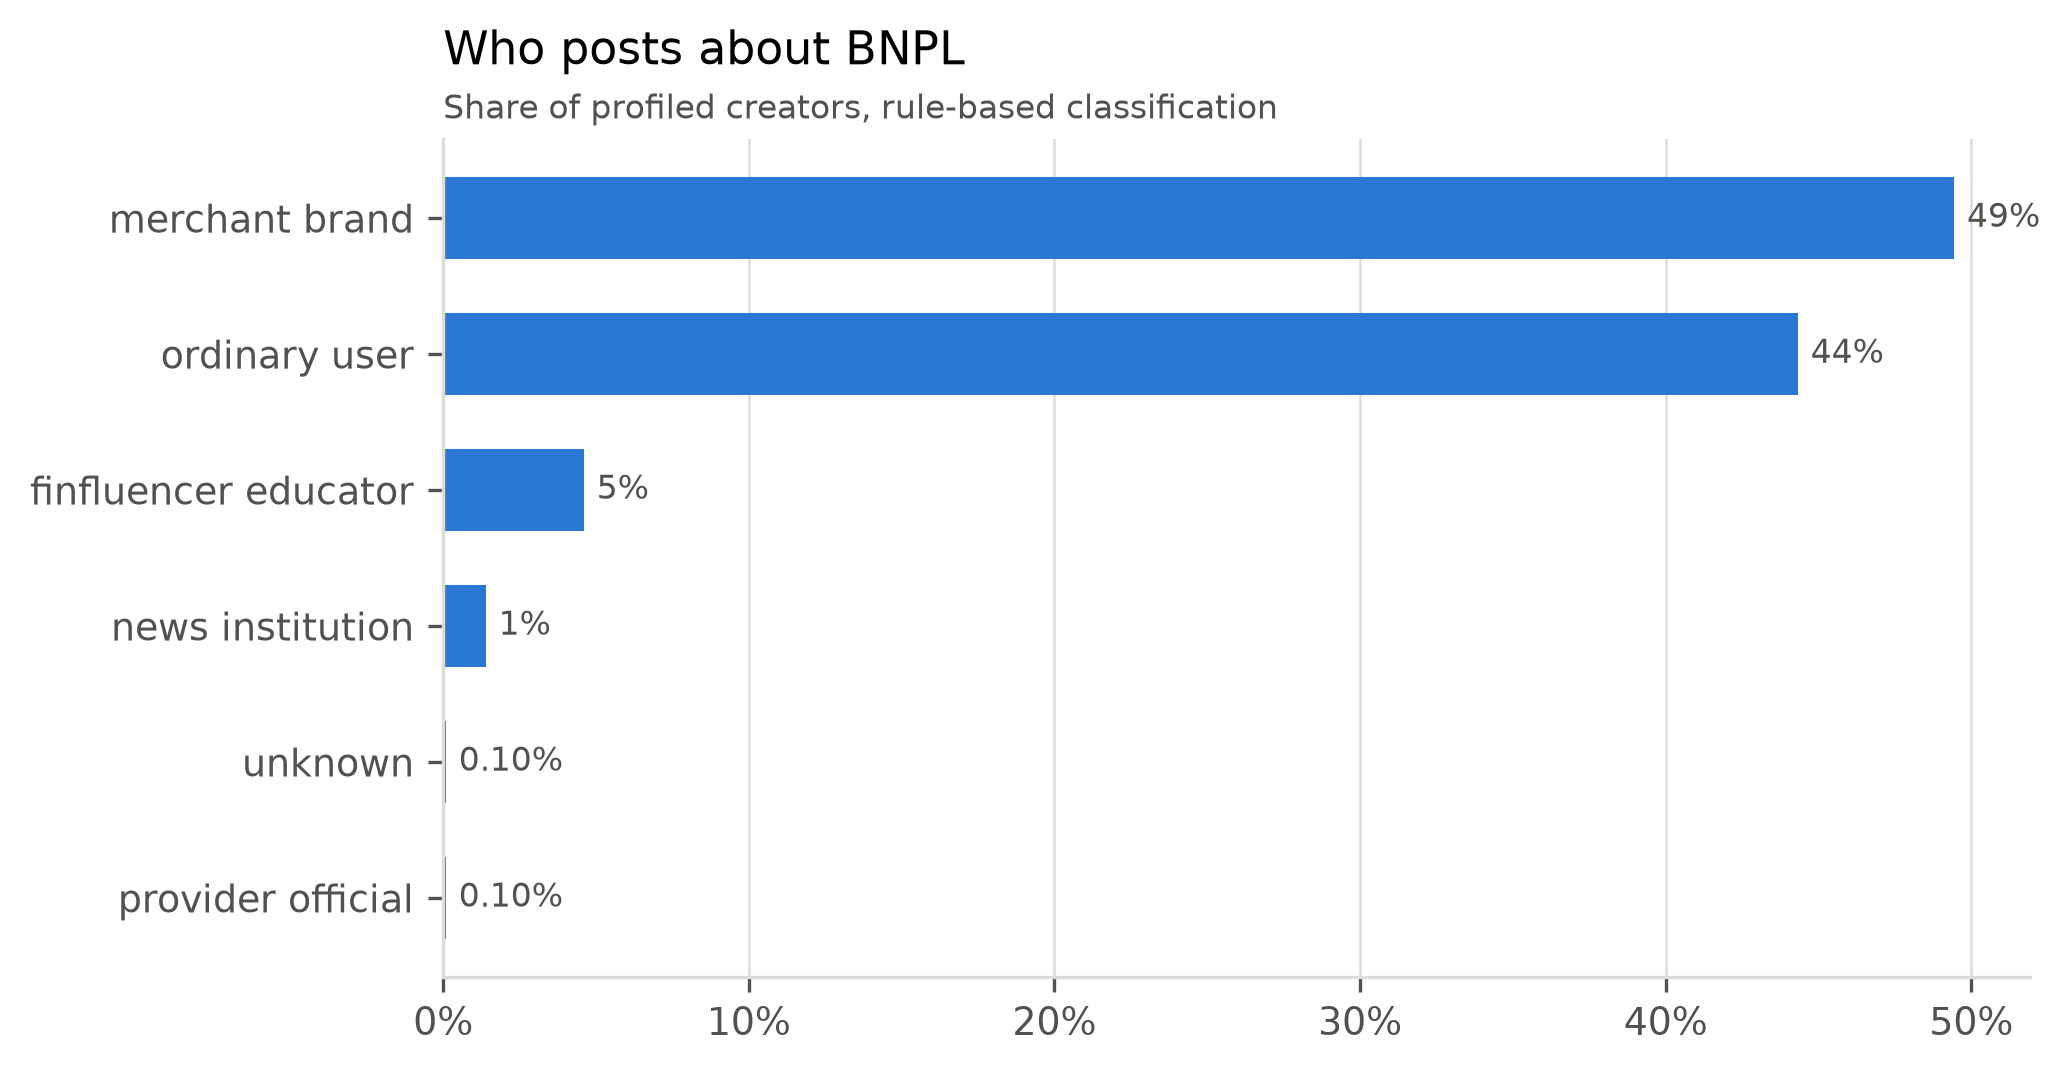

In [6]:
display(tables['creator_types'])
show('creator_types')

**Interpretation.** Among the 997 profiled creators, 49% are merchants and 44% have ordinary profiles. Finfluencers and educators make up 5%, and news outlets and institutions 1%.

Only one profile belongs to a BNPL provider. Providers do not promote BNPL on Italian TikTok themselves; the merchants who offer it at checkout do.

The share of ordinary profiles is overstated, for two reasons:
- every creator of a non-ad post was profiled on purpose;
- many small shops have no bio and post BNPL in only a few videos, so the rules cannot recognize them as merchants.

The remaining profiles will be added when the collection is rerun.

## 4. Providers

,provider,videos,creators,share_shop_ad
0,klarna,68966,5784,0.907
1,scalapay,28256,1964,0.936
2,heylight,3107,484,0.930
3,paypal_pay_in_3,2593,290,0.988
4,pagodil,1197,217,0.846
5,amazon_installments,7,6,0.714
6,soisy,2,2,1.000


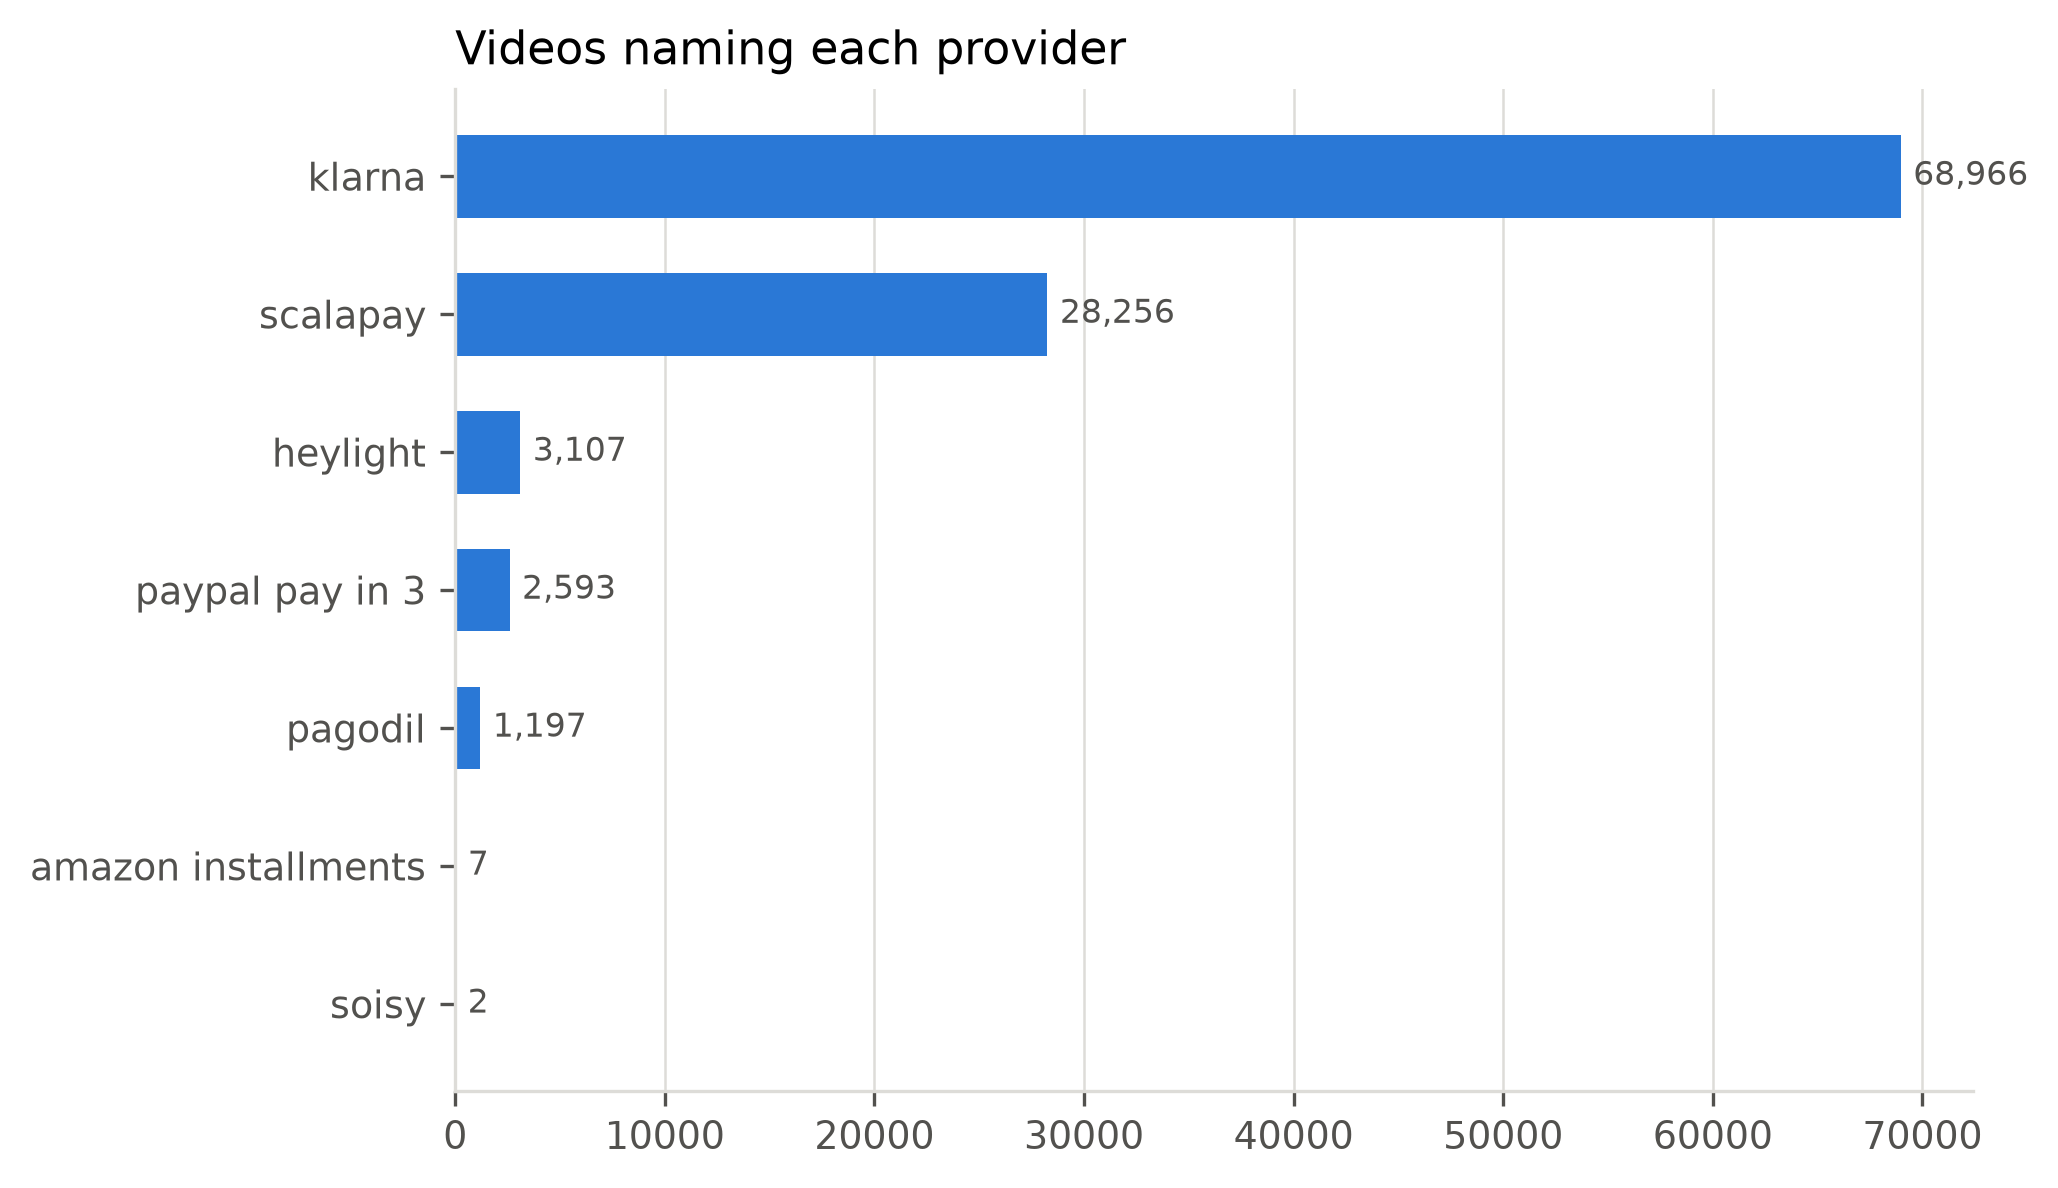

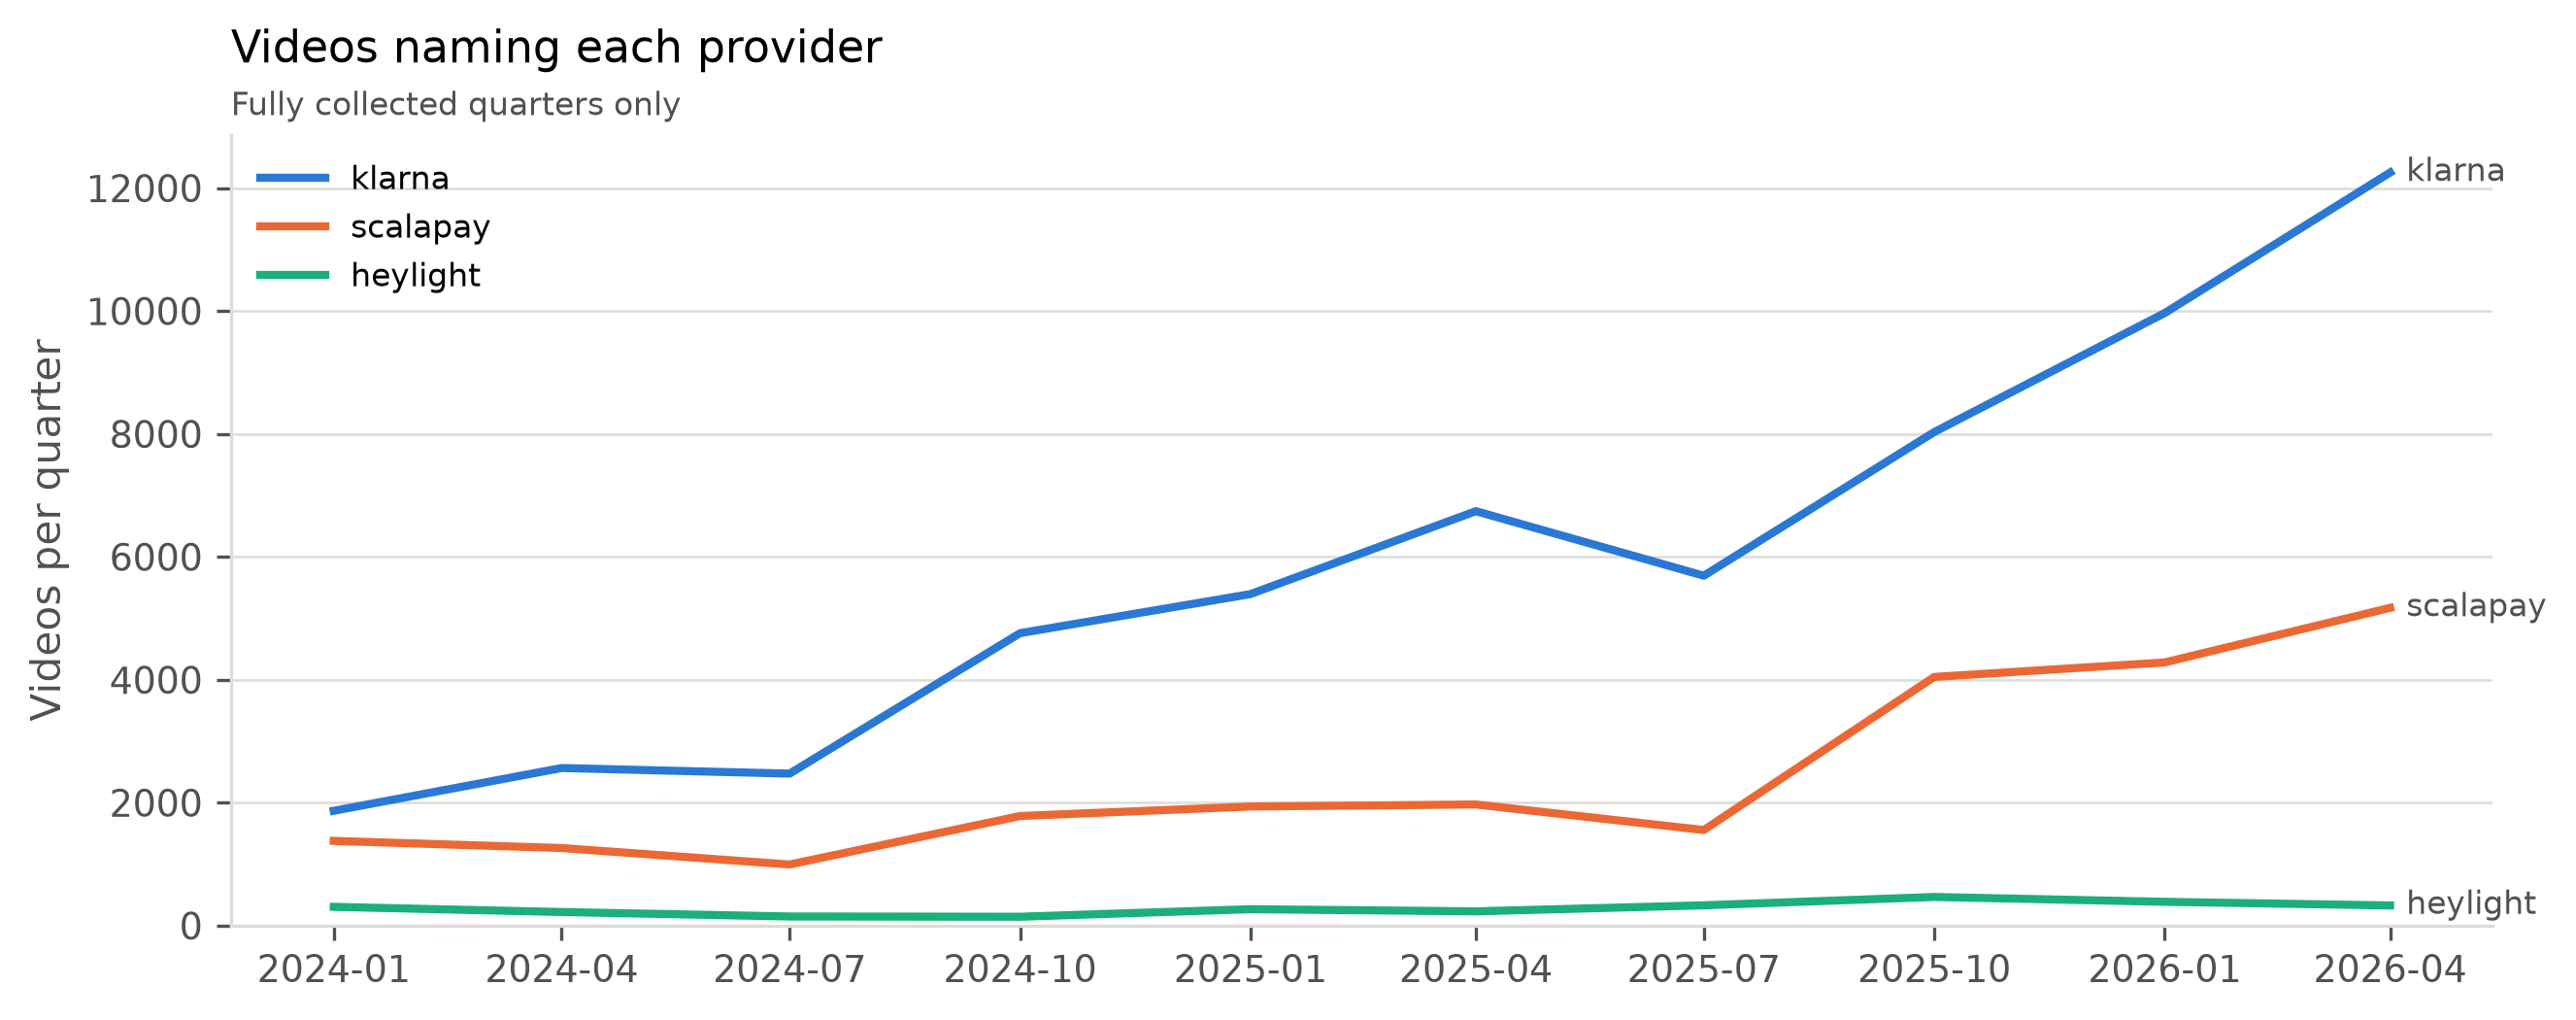

In [7]:
display(tables['providers'])
show('providers')
show('provider_trends')

**Interpretation.** Klarna is the default BNPL brand on Italian TikTok. It accounts for 66% of all provider mentions: 68,966 videos from 5,784 accounts. Next come:
- Scalapay: 28,256 videos;
- HeyLight: 3,107;
- PayPal's pay in 3: 2,593;
- PagoDIL: 1,197.

Every provider appears in ads 85-99% of the time.

Growth differs by provider. From the first quarter of 2024 to the second quarter of 2026, Klarna mentions grew 6.6 times (1,868 to 12,253) and Scalapay 3.8 times (1,378 to 5,170), with Scalapay jumping in Q4 2025. HeyLight and PagoDIL stayed flat.

One in six videos that names a provider (18%) names two or more, typically "paga con Klarna o Scalapay". The same shopper is routinely offered several providers side by side. This is the platform-level counterpart of the fragmentation across providers and apps that the thesis studies.

## 5. Themes mentioned

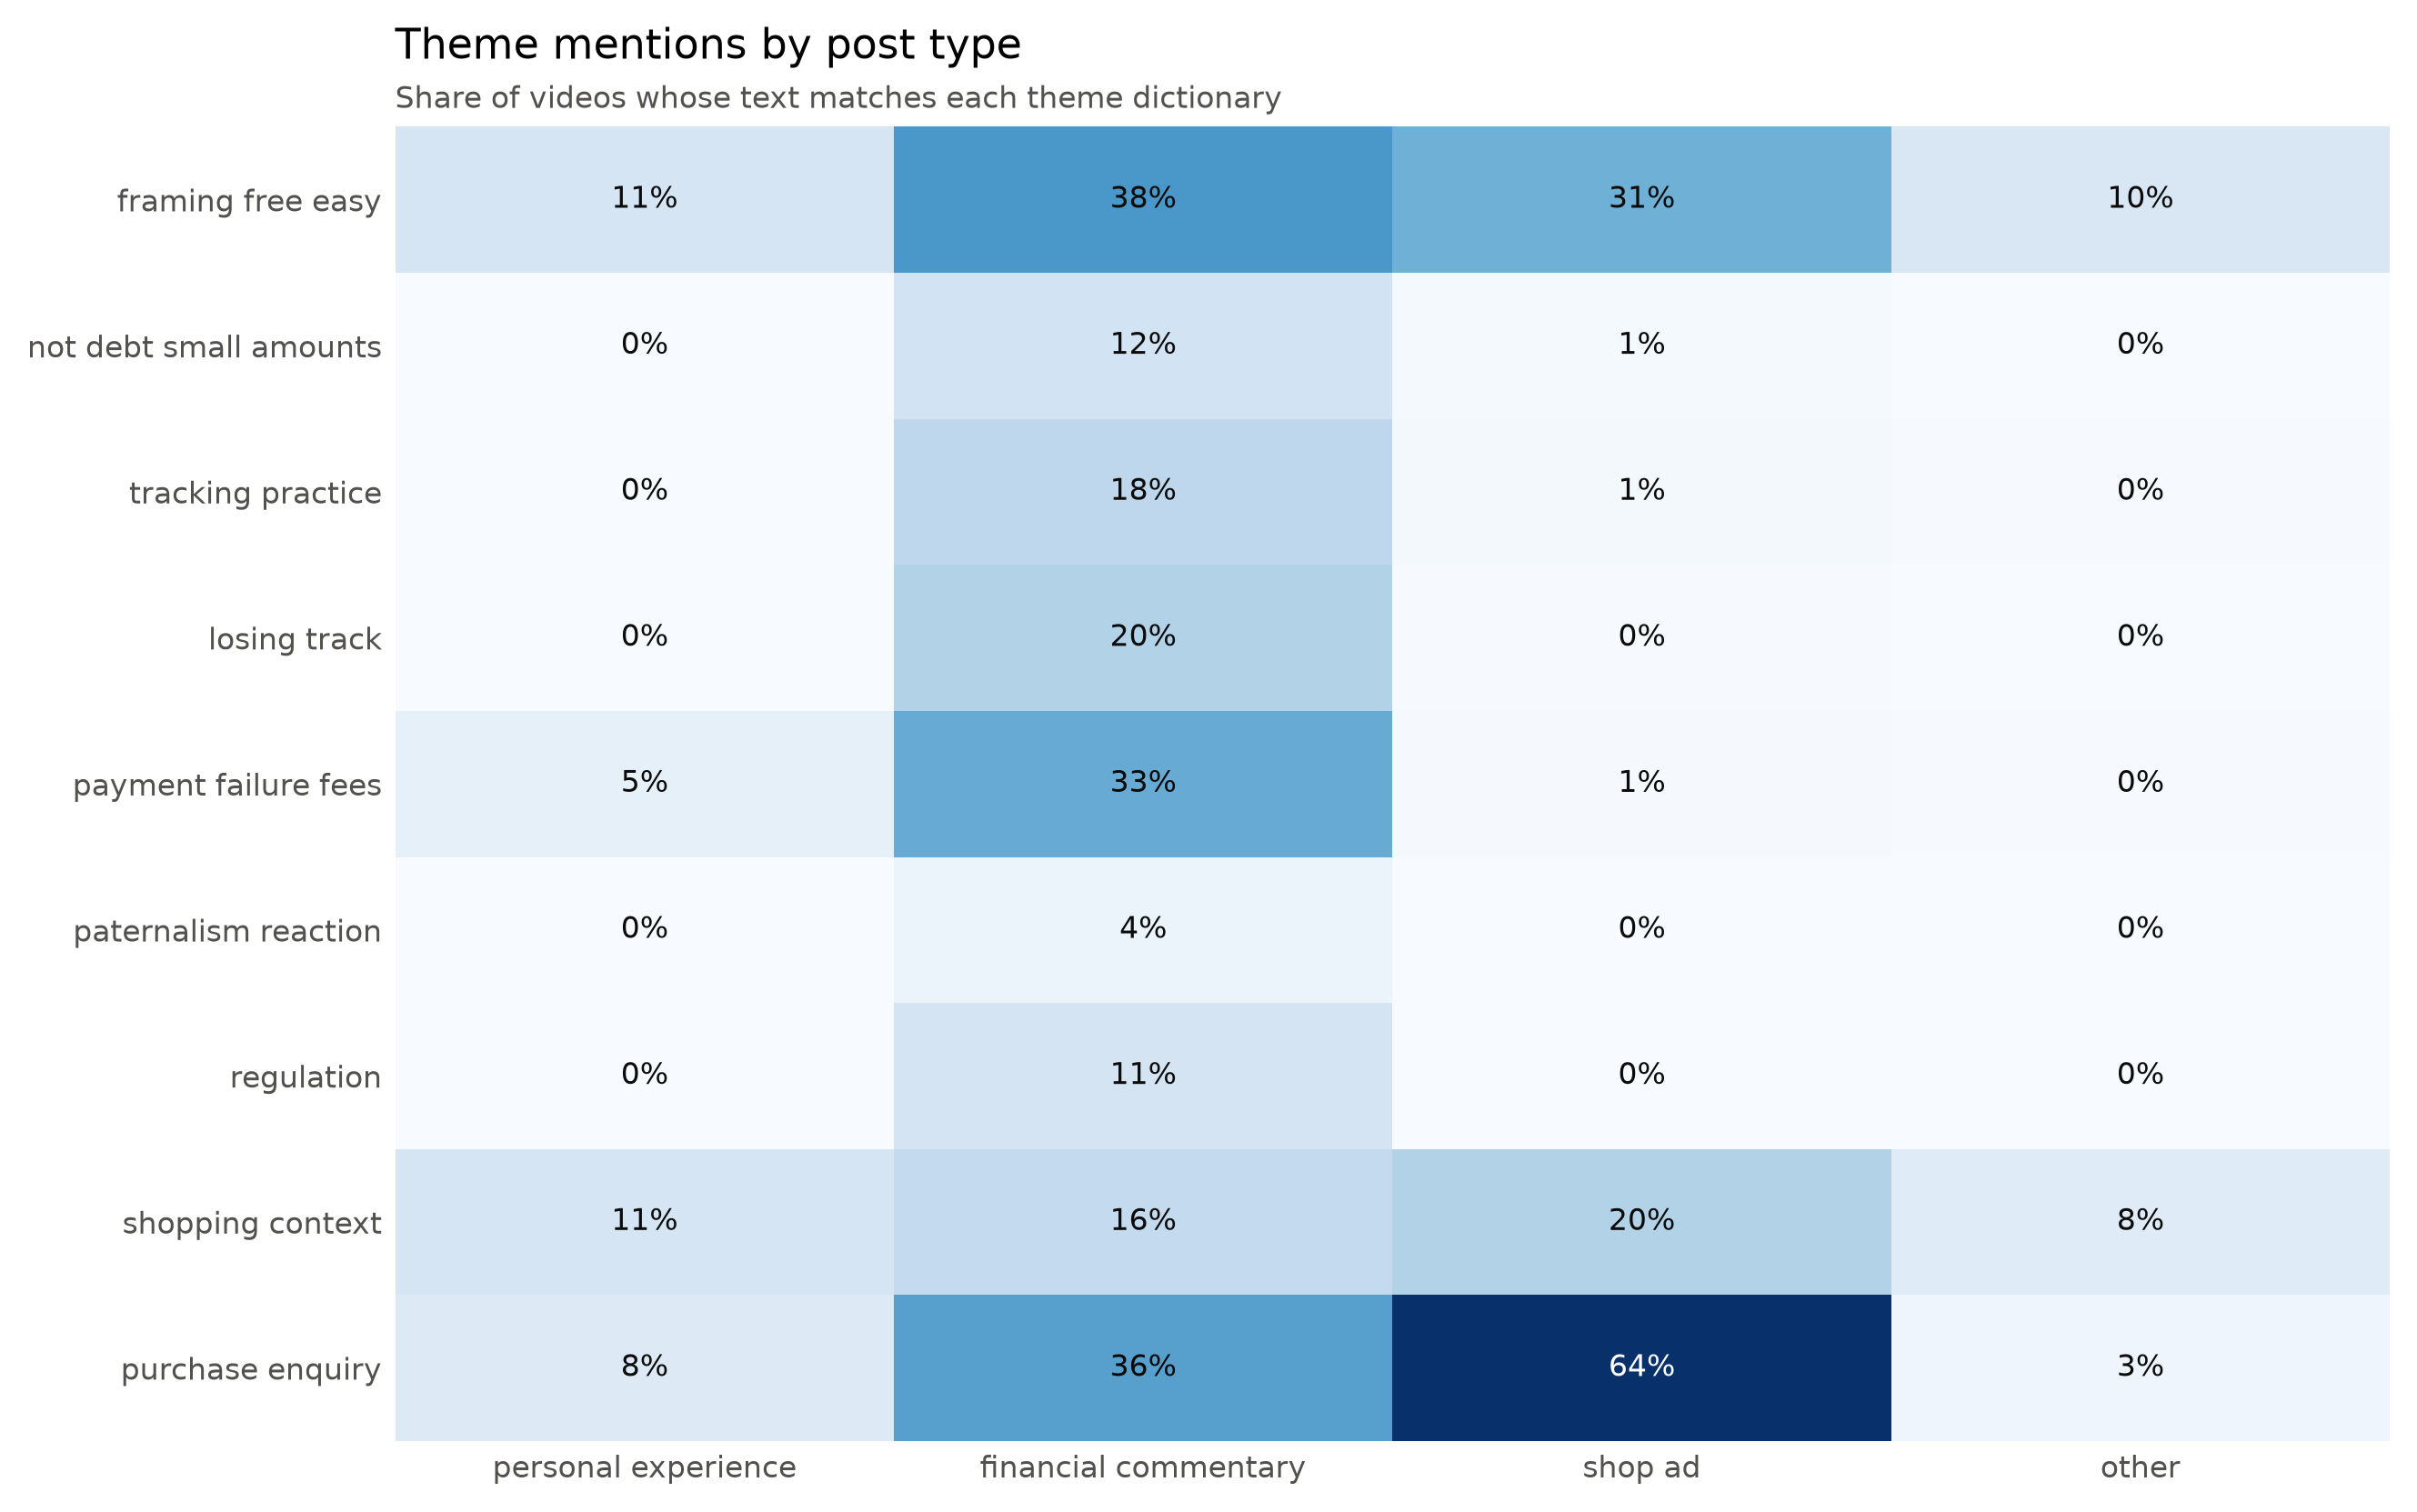

In [8]:
show('cues_by_post_type')

**Interpretation.** The two main post types tell two different stories about the same product.

**Shop ads.** The dominant message is that BNPL is free and easy: 31% of ads say "senza interessi", "0%", "comodo", or similar. Risk themes (fees, missed payments, losing track) appear in at most 1% of ads.

**Financial commentary.** The picture reverses:
- payment failure and fees: 33%;
- losing track of installments: 20%;
- tracking practices: 18%;
- the "it's not debt, it's only a few euros" framing, usually quoted in order to challenge it: 12%;
- regulation: 11%.

Commentary also quotes the free-and-easy language (38%), mostly to contest it. Typical arguments are that "3 rate senza interessi" is "a credit contract, not a harmless button", or that "30 € + 25 € + 40 € + 50 €" adds up without being noticed.

This is the visibility problem the thesis addresses, voiced by educators. It reaches far fewer viewers than the free-and-easy message.

Shares are keyword matches in short texts, and first-person posts are too few (37) to compare.

## 6. Black Friday

year,2024,2025
week_offset,,
-6,80.000,99.000
-5,85.000,105.000
-4,86.000,116.000
-3,92.000,55.000
-2,138.000,103.000
-1,119.000,122.000
0,68.000,115.000
1,107.000,115.000
2,117.000,110.000


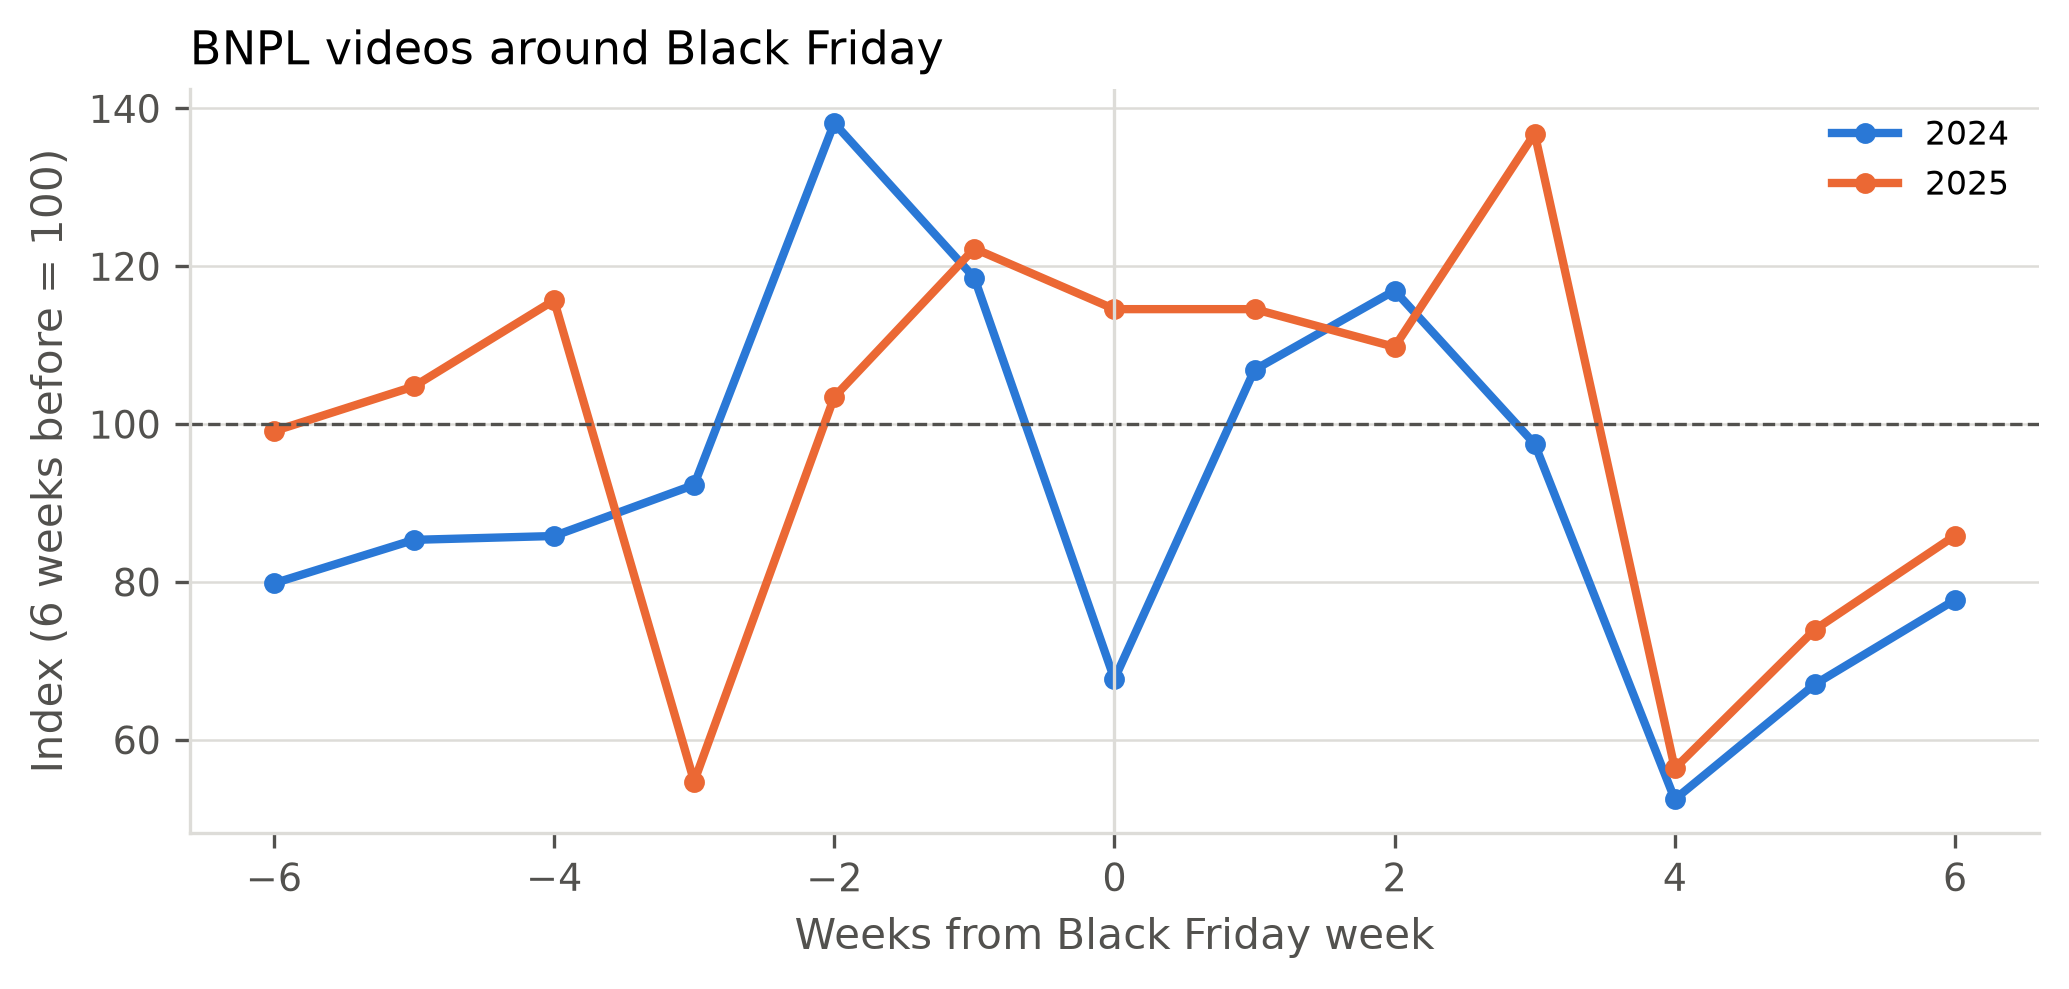

In [9]:
display(tables['black_friday'].pivot_table(index='week_offset', columns='year', values='index').round(0))
show('black_friday')

**Interpretation.** Volume does not reliably peak in Black Friday week.
- **2024:** volume rose two weeks before Black Friday (index 138), then fell in Black Friday week itself (68).
- **2025:** volume stayed 10-20% above the baseline from Black Friday week to three weeks after (peak 137).
- **Both years:** volume falls to about 55 in Christmas week (four weeks after).

Single weeks also swing by ±40% without an obvious cause, such as 55 three weeks before Black Friday 2025. Weekly counts are therefore noisy.

The defensible reading is that posting is driven by shops' routine rather than by sales events. Posting volume is not purchase volume, and these data say nothing about how much BNPL is used on Black Friday.

## 7. Context hashtags

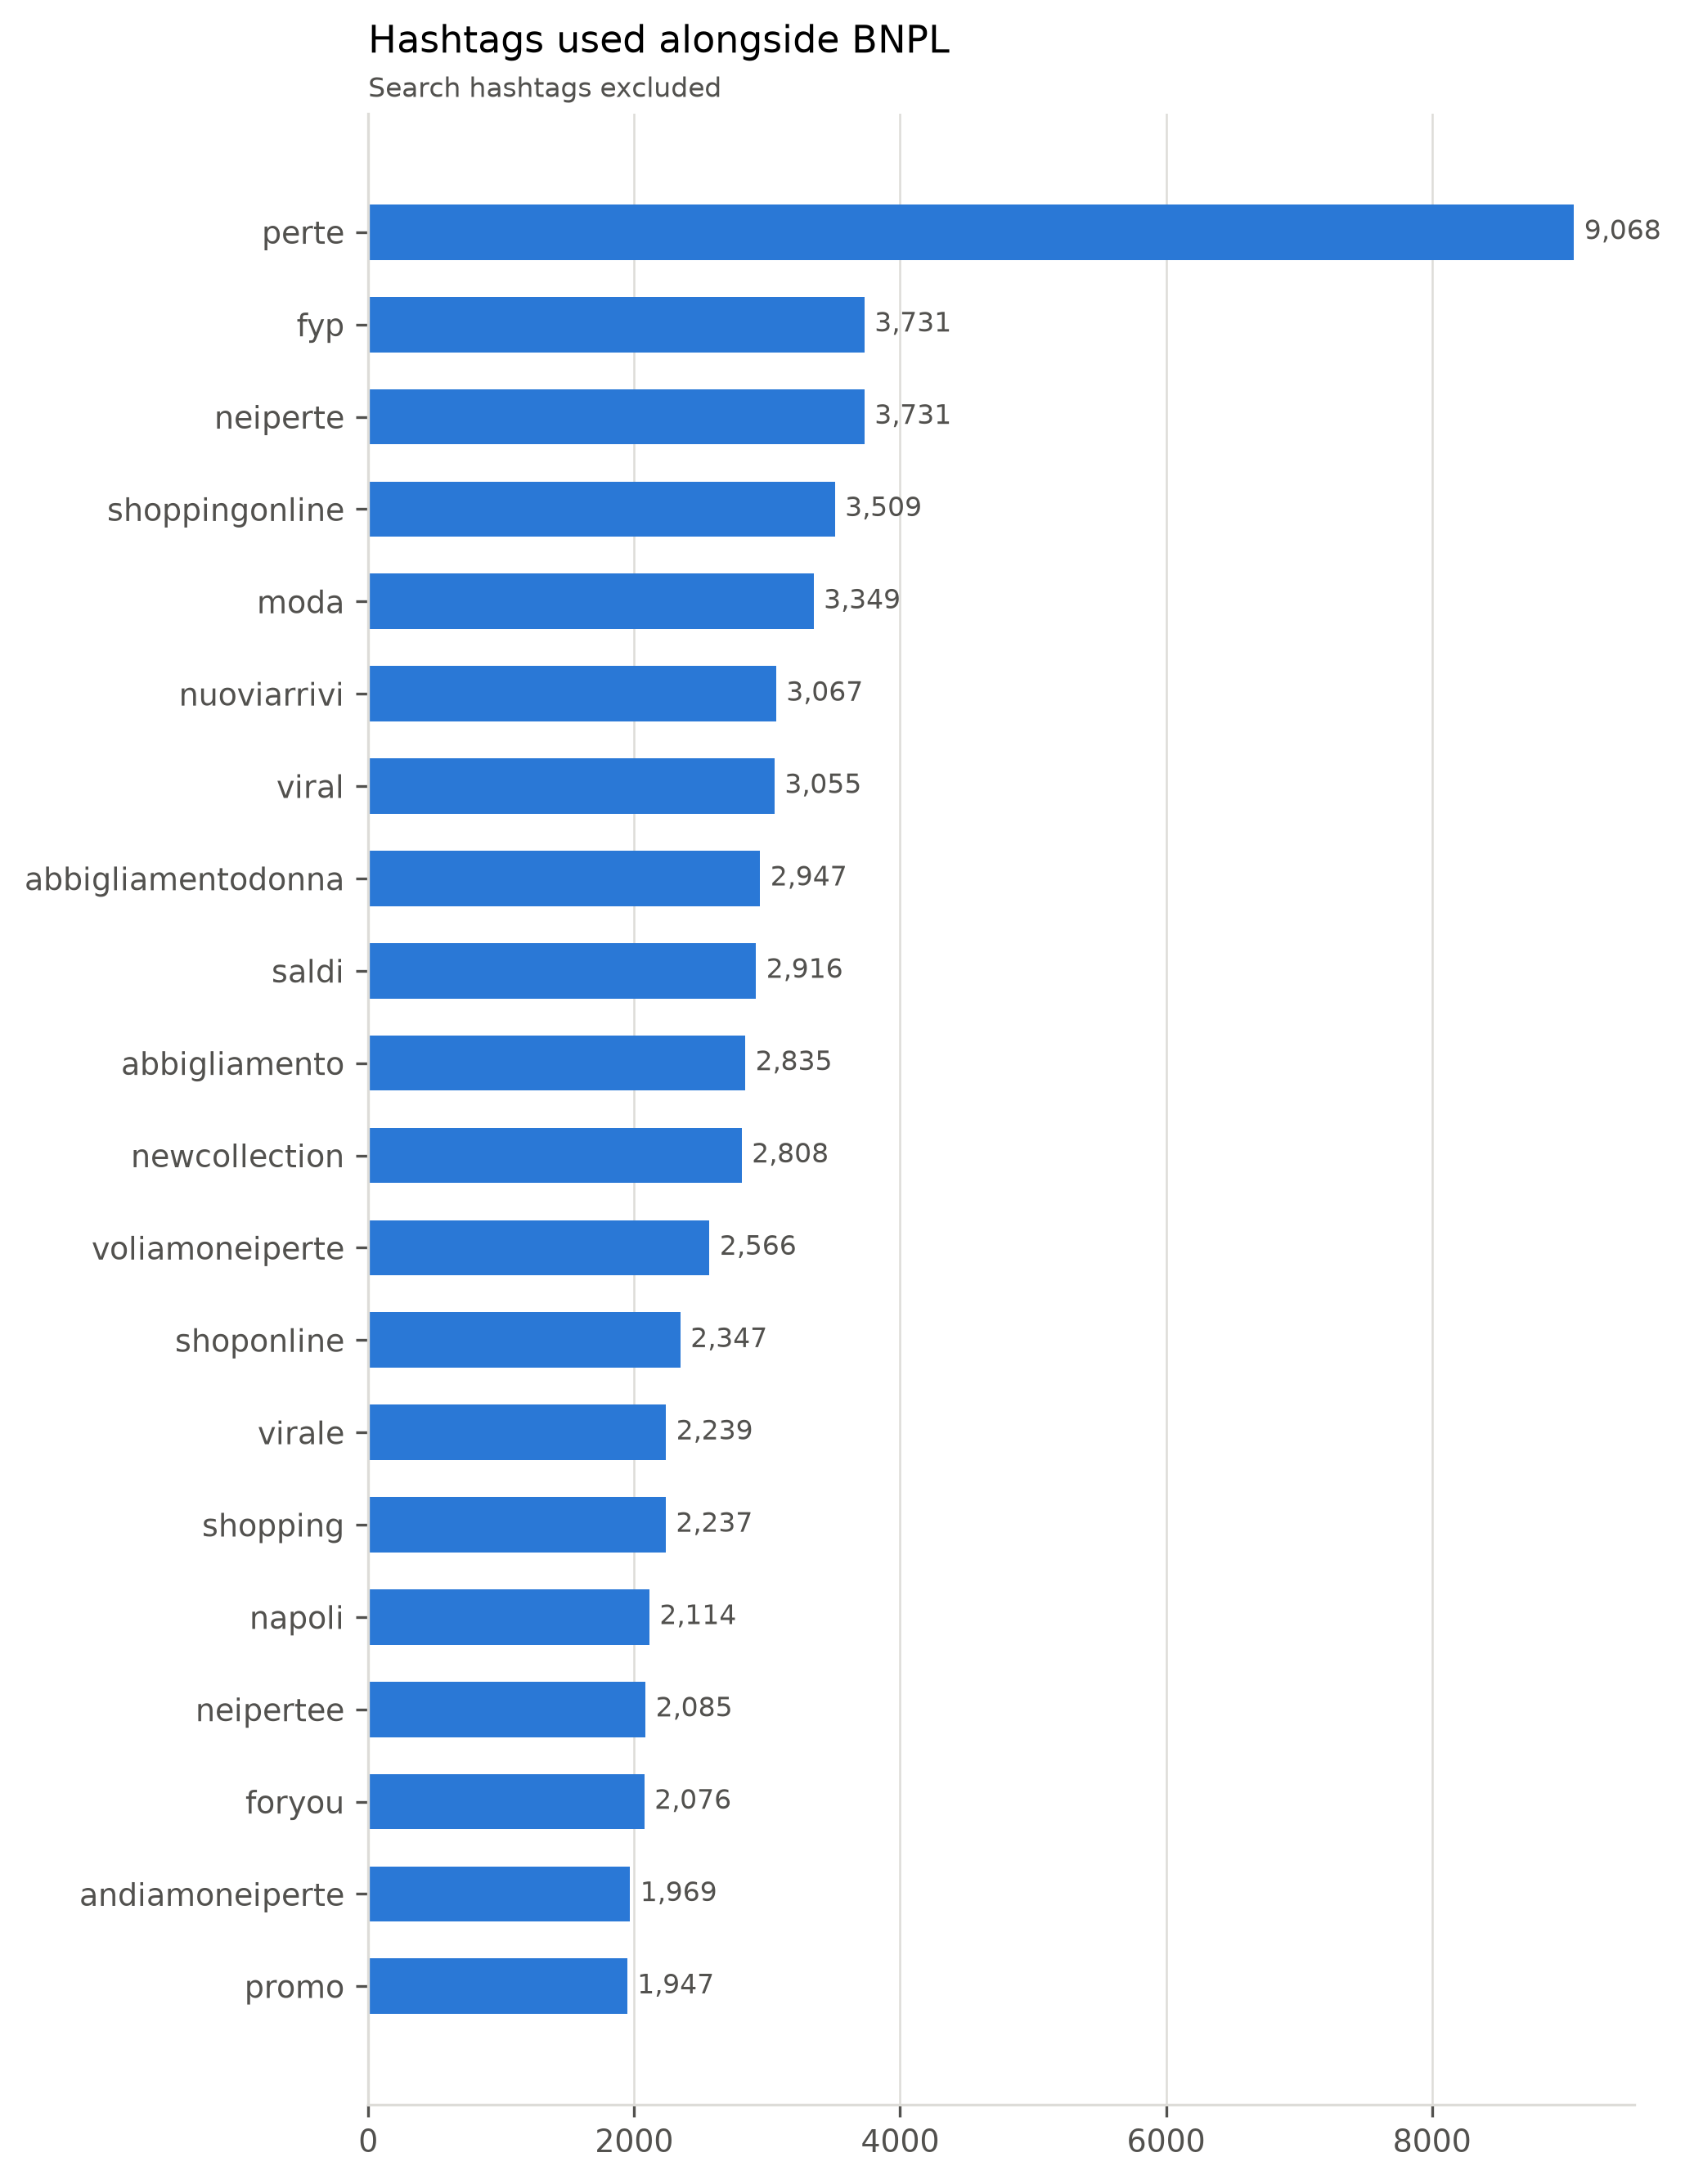

In [10]:
show('top_hashtags')

**Interpretation.** Apart from the search terms, the hashtags used alongside BNPL fall into two groups:
- general reach hashtags: #perte, #neiperte, #fyp, #viral;
- clothing and shoe retail: #moda, #abbigliamento, #nuoviarrivi, #newcollection, #saldi, #shoppingonline.

#napoli is the only place name in the top 20, on 2% of videos. The typical BNPL video is a small fashion retailer showing new stock with "paga in 3 rate".

Fashion is where most of this content comes from, so a fashion checkout is a realistic scenario for the thesis prototype.

## 8. Comments

,comments
video_post_type,
shop_ad,10563
other,5940
financial_commentary,1316
personal_experience,259


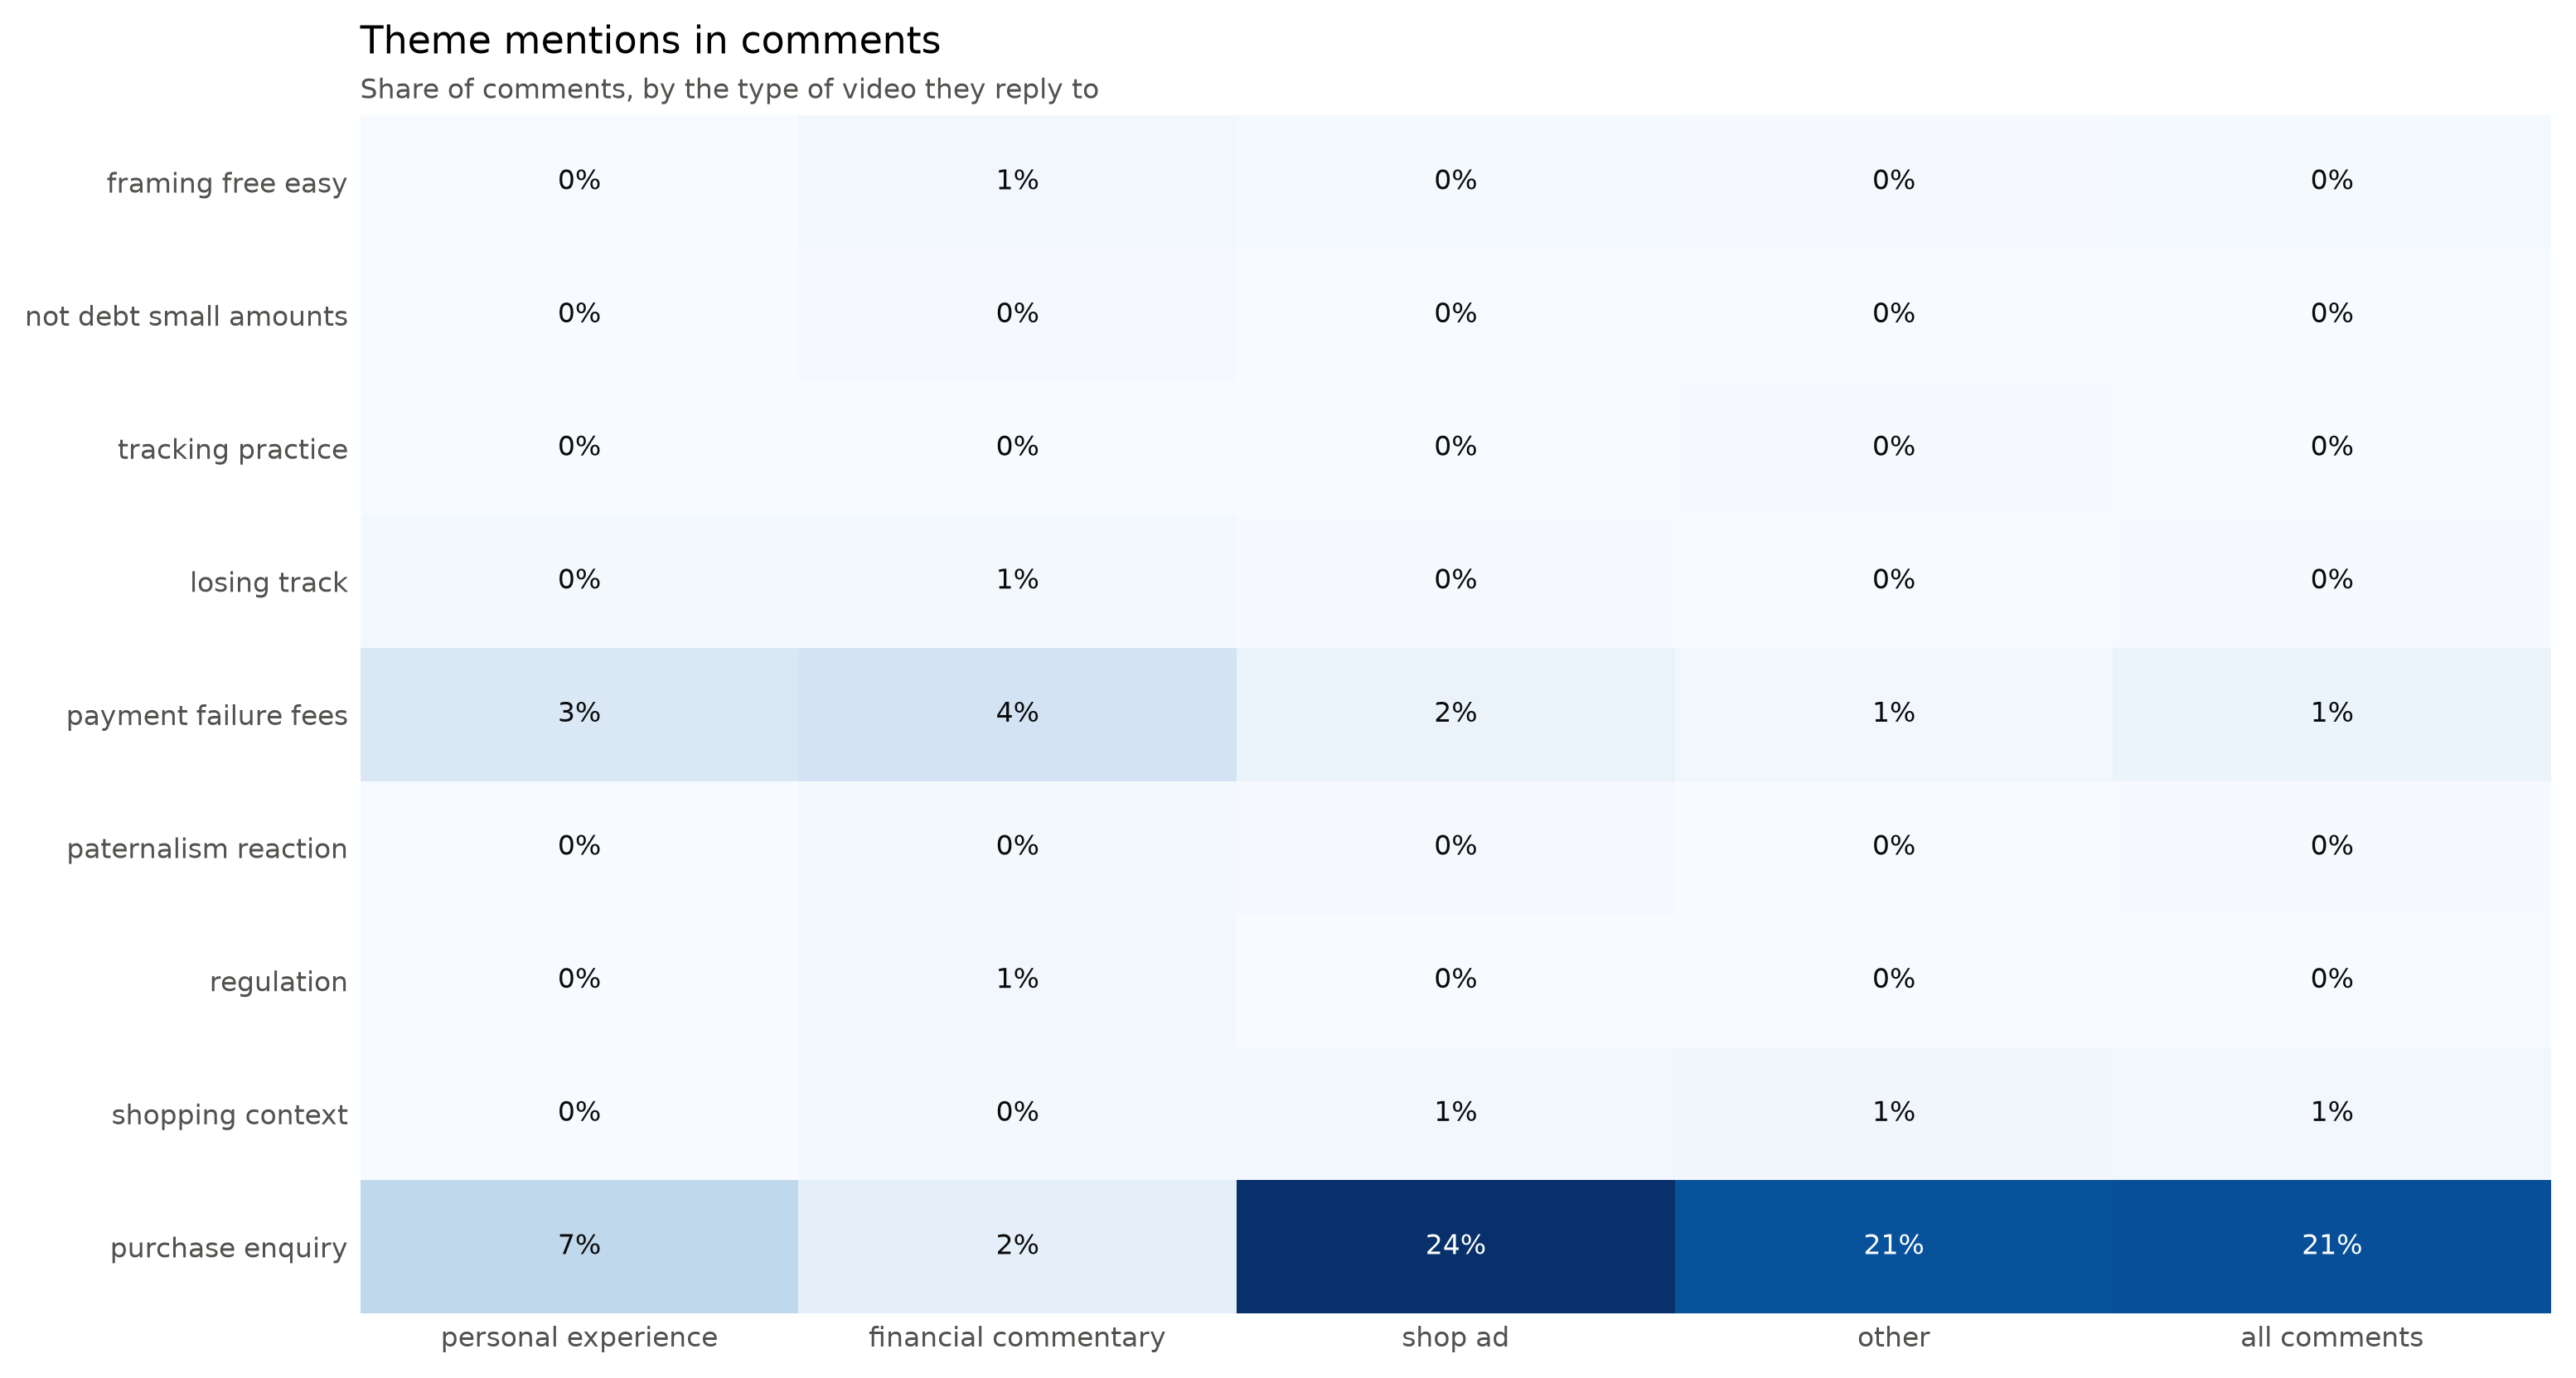

In [11]:
display(result['comments']['video_post_type'].value_counts().rename('comments').to_frame())
show('comment_cues')

**Interpretation.** The 18,078 comments come from 309 videos, and most sit under ads (10,563) or unclassified posts (5,940). Under ads, comments work as customer service: 24% ask about price, availability, shipping, or where to buy, against 2% under commentary.

Theme words are rare in comments, because comments are short and the dictionaries are lexical. Payment failure and fees is the most frequent theme: 4% of comments under commentary and 3.5% under first-person posts.

Reading comments under commentary videos shows that discussion drifts to wages, the cost of living, and blame ("la gente", "colpa"), rather than to how people keep track of their own installments.

For the thesis: TikTok shows how BNPL is sold and how it is criticized, but not how users manage their commitments. That evidence has to come from the interviews and the artefact walk-throughs.

## 9. Before and after CCD2

In [12]:
display(tables['cues_by_period'])

,cue,pre_ccd2
0,framing_free_easy,0.295
1,not_debt_small_amounts,0.009
2,tracking_practice,0.011
3,losing_track,0.004
4,payment_failure_fees,0.006
5,paternalism_reaction,0.001
6,regulation,0.002
7,shopping_context,0.188
8,purchase_enquiry,0.585


**Interpretation.** No post-CCD2 data exists yet: the revised Consumer Credit Directive applies from 20 November 2026, so the table has only the `pre_ccd2` column. This is the baseline. Regulation is mentioned in 0.2% of BNPL videos overall, but in 11% of commentary. Posts explicitly explaining the directive appear from August and September 2026.

Rerun the collection notebook after the end of December 2026, and again after January 2027. That adds the weeks after the directive applies, including Black Friday 2026 and Christmas. The before-and-after table and heatmap (`cues_by_period.png`) then appear automatically.

## 10. Summary for the thesis

**What the TikTok corpus contributes to the thesis** (run of 26 October 2026, January 2024 to August 2026, 97,166 BNPL videos):

1. **BNPL reaches young people on TikTok mainly as a merchant feature.** 91% of BNPL videos are shop ads. The 100 most active accounts produce 47% of the content, and provider accounts are almost absent.
2. **The promoted message is "free and easy".** 31% of ads stress no interest or ease, and almost none mention fees, missed payments, or totals.
3. **Fragmentation is visible at checkout.** Klarna dominates (66% of mentions, growing 6.6 times since early 2024), and 18% of provider videos offer two or more providers side by side.
4. **Critical discourse is small but growing, and it targets the thesis problem.** Commentary rose from 14 videos in 2024 to 85 in the first nine months of 2026. A third of it discusses fees and failures, a fifth discusses losing track of installments, and it peaked in August 2026 around BNPL for groceries and holidays.
5. **TikTok does not show how users track their commitments.** First-person accounts are rare (37 videos) and comments are mostly purchase questions, which supports interviews and artefact elicitation as the main evidence for RQ1 and RQ2.

**Limits.** Labels are keyword rules applied to captions, hashtags, and transcripts, so they are not validated codes. The data covers accounts registered in Italy and says nothing about viewers or their age. Volume reflects platform growth and API coverage as well as BNPL adoption.